
# Option Pricing & Greeks — Black–Scholes, Monte Carlo, Binomial

This notebook implements:
- **Black–Scholes** (closed-form) prices and Greeks (Delta, Gamma, Vega)
- **Monte Carlo** simulation with common random numbers and 95% CIs
- **CRR Binomial Tree** with prices and Greeks
- **Convergence** experiments (MC paths, binomial steps) and a summary table

Parameters used: S₀ = 40, K = 40, r = 3.2%, σ = 20%, T = 1/3 year (no dividends).


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import erf

# Parameters
S0, K, r, sigma, T = 40.0, 40.0, 0.032, 0.20, 1/3
MC_SIZES = [1_000, 3_000, 10_000, 30_000, 100_000, 300_000]
BINOM_STEPS = [10, 25, 50, 100, 200, 400, 800, 1600]
SEED = 42


In [2]:

def norm_cdf(x): 
    return 0.5*(1.0 + erf(x/np.sqrt(2.0)))

def norm_pdf(x): 
    return (1.0/np.sqrt(2.0*np.pi))*np.exp(-0.5*x*x)

def bs_d1(S,K,r,sigma,T): 
    return (np.log(S/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))

def bs_d2(S,K,r,sigma,T): 
    return bs_d1(S,K,r,sigma,T) - sigma*np.sqrt(T)

def bs_call_price(S,K,r,sigma,T):
    d1, d2 = bs_d1(S,K,r,sigma,T), bs_d2(S,K,r,sigma,T)
    return S*norm_cdf(d1) - K*np.exp(-r*T)*norm_cdf(d2)

def bs_put_price(S,K,r,sigma,T):
    d1, d2 = bs_d1(S,K,r,sigma,T), bs_d2(S,K,r,sigma,T)
    return K*np.exp(-r*T)*norm_cdf(-d2) - S*norm_cdf(-d1)

def bs_call_delta(S,K,r,sigma,T): 
    return norm_cdf(bs_d1(S,K,r,sigma,T))

def bs_put_delta(S,K,r,sigma,T): 
    return bs_call_delta(S,K,r,sigma,T) - 1.0

def bs_gamma(S,K,r,sigma,T): 
    return norm_pdf(bs_d1(S,K,r,sigma,T))/(S*sigma*np.sqrt(T))

def bs_vega(S,K,r,sigma,T): 
    return S*norm_pdf(bs_d1(S,K,r,sigma,T))*np.sqrt(T)  # per 1.00 change in sigma


In [3]:

bs = {
    "Call Price": bs_call_price(S0,K,r,sigma,T),
    "Put Price":  bs_put_price(S0,K,r,sigma,T),
    "Call Delta": bs_call_delta(S0,K,r,sigma,T),
    "Put Delta":  bs_put_delta(S0,K,r,sigma,T),
    "Gamma":      bs_gamma(S0,K,r,sigma,T),
    "Vega":       bs_vega(S0,K,r,sigma,T)
}
pd.DataFrame(bs, index=["Black–Scholes"]).T.round(6)


,Black–Scholes
Call Price,2.051844
Put Price,1.627445
Call Delta,0.559662
Put Delta,-0.440338
Gamma,0.085406
Vega,9.109958


In [9]:

def mc_price_greeks(S0, K, r, sigma, T, N, greek_bump_frac_S=0.01, greek_bump_abs_sigma=0.01, seed=SEED):
    rng = np.random.default_rng(seed)
    Z = rng.standard_normal(N)
    drift = (r - 0.5*sigma**2)*T
    volterm = sigma*np.sqrt(T)
    ST = S0*np.exp(drift + volterm*Z)
    disc = np.exp(-r*T)
    # Prices
    call_payoff = np.maximum(ST - K, 0.0)
    put_payoff  = np.maximum(K - ST, 0.0)
    call = disc * call_payoff.mean()
    put  = disc * put_payoff.mean()
    # SEs & 95% CIs
    call_se = disc * call_payoff.std(ddof=1)/np.sqrt(N)
    put_se  = disc * put_payoff.std(ddof=1)/np.sqrt(N)
    call_ci = 1.96*call_se
    put_ci  = 1.96*put_se
    # Greeks via CRNs bumps
    dS = greek_bump_frac_S*S0
    ST_up = (S0 + dS)*np.exp(drift + volterm*Z)
    ST_dn = (S0 - dS)*np.exp(drift + volterm*Z)
    call_up = disc*np.maximum(ST_up-K,0.0).mean()
    call_dn = disc*np.maximum(ST_dn-K,0.0).mean()
    put_up  = disc*np.maximum(K-ST_up,0.0).mean()
    put_dn  = disc*np.maximum(K-ST_dn,0.0).mean()
    delta_c = (call_up - call_dn)/(2*dS)
    delta_p = (put_up  - put_dn )/(2*dS)
    gamma   = (call_up - 2*call + call_dn)/(dS**2)
    # Vega via sigma bump
    dsig = greek_bump_abs_sigma
    sig_up = sigma + dsig
    sig_dn = max(1e-8, sigma - dsig)
    ST_su = S0*np.exp((r - 0.5*sig_up**2)*T + sig_up*np.sqrt(T)*Z)
    ST_sd = S0*np.exp((r - 0.5*sig_dn**2)*T + sig_dn*np.sqrt(T)*Z)
    call_su = disc*np.maximum(ST_su-K,0.0).mean()
    call_sd = disc*np.maximum(ST_sd-K,0.0).mean()
    vega = (call_su - call_sd)/(2*dsig)
    return {
        "Call Price": call, "Put Price": put,
        "Call 95% CI ±": call_ci, "Put 95% CI ±": put_ci,
        "Call Delta": delta_c, "Put Delta": delta_p,
        "Gamma": gamma, "Vega": vega
    }


,Call Price,Put Price,Call 95% CI ±,Put 95% CI ±,Call Delta,Put Delta,Gamma,Vega
N,,,,,,,,
1000,1.937331,1.652522,0.180826,0.149958,0.555149,-0.441362,0.075214,8.489912
3000,1.990321,1.680006,0.106706,0.087747,0.556982,-0.440166,0.087227,8.777099
10000,2.029034,1.648609,0.059513,0.047175,0.554248,-0.444653,0.094469,9.014102
30000,2.078218,1.613755,0.034675,0.026820,0.562341,-0.438660,0.089785,9.252240
100000,2.045498,1.638590,0.018849,0.014781,0.556261,-0.443302,0.088886,9.093175
300000,2.052591,1.627505,0.010876,0.008483,0.558975,-0.441042,0.085903,9.119105


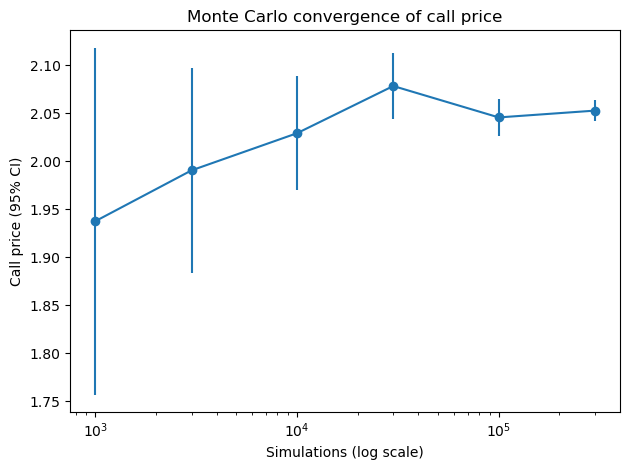

In [5]:

# Convergence sweep
mc_rows = []
for N in MC_SIZES:
    mc_rows.append({"N": N, **mc_price_greeks(S0,K,r,sigma,T,N)})
mc_df = pd.DataFrame(mc_rows).set_index("N").round(6)
display(mc_df)

# Plot convergence (call)
plt.figure()
plt.errorbar(mc_df.index, mc_df["Call Price"], yerr=mc_df["Call 95% CI ±"], fmt='o-')
plt.xscale('log')
plt.xlabel("Simulations (log scale)")
plt.ylabel("Call price (95% CI)")
plt.title("Monte Carlo convergence of call price")
plt.tight_layout()
plt.show()


In [6]:

def binomial_pricer(S0,K,r,sigma,T,steps, option_type="call"):
    dt = T/steps
    u = np.exp(sigma*np.sqrt(dt)); d = 1.0/u
    p = (np.exp(r*dt) - d)/(u - d)
    disc = np.exp(-r*dt)
    # terminal prices
    ST = S0*(u**np.arange(steps, -1, -1))*(d**np.arange(0, steps+1, 1))
    if option_type=="call":
        V = np.maximum(ST - K, 0.0)
    else:
        V = np.maximum(K - ST, 0.0)
    for _ in range(steps,0,-1):
        V = disc*(p*V[:-1] + (1-p)*V[1:])
    return V[0]

def binomial_greeks(S0,K,r,sigma,T,steps, option_type="call"):
    # Price
    V0 = binomial_pricer(S0,K,r,sigma,T,steps, option_type)
    # Delta & Gamma via small S bumps (same lattice size)
    dS = 0.01*S0
    V_up = binomial_pricer(S0+dS,K,r,sigma,T,steps, option_type)
    V_dn = binomial_pricer(S0-dS,K,r,sigma,T,steps, option_type)
    delta = (V_up - V_dn)/(2*dS)
    gamma = (V_up - 2*V0 + V_dn)/(dS**2)
    # Vega via sigma bump
    dsig = 0.01
    V_su = binomial_pricer(S0,K,r,sigma+dsig,T,steps, option_type)
    V_sd = binomial_pricer(S0,K,r,max(1e-8, sigma-dsig),T,steps, option_type)
    vega = (V_su - V_sd)/(2*dsig)
    return V0, delta, gamma, vega


,Call Price,Put Price,Call Delta,Put Delta,Gamma,Vega
Steps,,,,,,
10,2.006499,1.582099,0.558205,-0.441795,0.608341,8.885280
25,2.069972,1.645572,0.560258,-0.439742,-0.000000,9.202335
50,2.042669,1.618270,0.559367,-0.440633,0.277543,9.064413
100,2.047251,1.622851,0.559514,-0.440486,0.196744,9.087101
200,2.049546,1.625146,0.559588,-0.440412,0.139293,9.098467
400,2.050694,1.626295,0.559625,-0.440375,0.098557,9.104156
800,2.051269,1.626870,0.559496,-0.440504,0.095238,9.107002
1600,2.051556,1.627157,0.559557,-0.440443,0.090926,9.108425


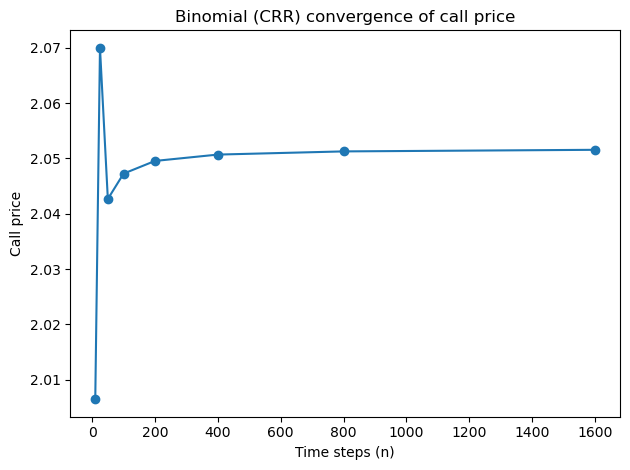

In [7]:

rows = []
for n in BINOM_STEPS:
    c, cDelta, cGamma, cVega = binomial_greeks(S0,K,r,sigma,T,n,"call")
    p, pDelta, pGamma, pVega = binomial_greeks(S0,K,r,sigma,T,n,"put")
    rows.append({
        "Steps": n,
        "Call Price": c, "Put Price": p,
        "Call Delta": cDelta, "Put Delta": pDelta,
        "Gamma": 0.5*(cGamma+pGamma),  # should be similar
        "Vega": cVega  # similar for call/put here
    })
binom_df = pd.DataFrame(rows).set_index("Steps").round(6)
display(binom_df)

# Plot convergence (call price)
plt.figure()
plt.plot(binom_df.index, binom_df["Call Price"], marker='o')
plt.xlabel("Time steps (n)")
plt.ylabel("Call price")
plt.title("Binomial (CRR) convergence of call price")
plt.tight_layout()
plt.show()


In [8]:

best_mc = mc_df.iloc[-1]
best_binom = binom_df.iloc[-1]
summary = pd.DataFrame({
    "Call Price": [bs["Call Price"], best_mc["Call Price"], best_binom["Call Price"]],
    "Put Price":  [bs["Put Price"],  best_mc["Put Price"],  best_binom["Put Price"]],
    "Call Delta": [bs["Call Delta"], best_mc["Call Delta"], best_binom["Call Delta"]],
    "Put Delta":  [bs["Put Delta"],  best_mc["Put Delta"],  best_binom["Put Delta"]],
    "Gamma":      [bs["Gamma"],      best_mc["Gamma"],      best_binom["Gamma"]],
    "Vega":       [bs["Vega"],       best_mc["Vega"],       best_binom["Vega"]],
}, index=["Black–Scholes", f"Monte Carlo (N={MC_SIZES[-1]:,})", f"Binomial (n={BINOM_STEPS[-1]:,})"]).round(6)
summary


,Call Price,Put Price,Call Delta,Put Delta,Gamma,Vega
Black–Scholes,2.051844,1.627445,0.559662,-0.440338,0.085406,9.109958
"Monte Carlo (N=300,000)",2.052591,1.627505,0.558975,-0.441042,0.085903,9.119105
"Binomial (n=1,600)",2.051556,1.627157,0.559557,-0.440443,0.090926,9.108425
